<a href="https://colab.research.google.com/github/Baelfyre/MO-IT150_SPI_DataAnalytics_JobPosting_HEI_CoreCompetenciesAnalysis/blob/main/MO_IT150_SPI_DataAnalyticsJob_Posting%26_Curriculum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MO-IT150 SPI: Entry-Level Data Analytics Job Requirements and HEI Core Competencies

**Working study:**  
*Alignment Between Entry-Level Data Analyst Job Requirements and Fresh Graduate Qualifications Across Online Job Platforms and Local Employers in the Philippines*

## Mentor-feedback alignment

This notebook is structured around three requirements:

1. **Document the job-posting sample**: collection date/period, platform, inclusion criteria, employer identities, and posting counts.
2. **Use one graduate population consistently** and distinguish:
   - required vs preferred qualifications,
   - skills/tools vs experience,
   - academic preparation vs job readiness.
3. **Compare employer requirements with a graduate-competency/curriculum baseline** and explicitly acknowledge where that baseline is insufficient.

## Defined graduate population

For this analysis, the target population is:

> **Fresh graduates of Philippine computing and analytics-oriented bachelor's programs, including BS Information Technology, BS Information Systems, BS Computer Science, Data Science, Data Analytics, and Business Analytics programs, who are seeking entry-level Data Analyst or closely related analytics roles.**

Other degrees accepted by individual employers are retained as job-posting evidence, but they do not redefine the study population.

## Visualization strategy

Following the same question-driven approach used in the Machine Learning analysis, the notebook uses the smallest effective set of visuals:

**Analytical question → correct unit → evidence → visualization choice → interpretation → limitation → KEEP**

Only **three final visuals** are retained:

1. Experience evidence in entry-level roles
2. Explicitly required vs preferred tools
3. Employer competency evidence vs documented HEI competency coverage

The job-posting source inventory and employer identities are presented as tables because tables preserve source traceability better than charts for those requirements.


## 1. Setup and data loading

In [41]:
# @title
from pathlib import Path
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 140)

REPO = "Baelfyre/MO-IT150_SPI_DataAnalytics_JobPosting_HEI_CoreCompetenciesAnalysis"
BRANCH = "main"
RAW = f"https://raw.githubusercontent.com/{REPO}/{BRANCH}"

URLS = {
    "jobs_entry": f"{RAW}/data/cleaned/job_postings_entry_level_confirmed.csv",
    "jobs_all": f"{RAW}/data/cleaned/job_postings_direct_analytics_clean.csv",
    "job_profiles": f"{RAW}/data/cleaned/job_profiles_direct_analytics_dedup.csv",
    "skills_entry": f"{RAW}/data/cleaned/skills_entry_level_confirmed.csv",
    "hei_matrix": f"{RAW}/HEI/hei_core_competency_matrix.csv",
    "hei_inventory": f"{RAW}/HEI/hei_source_inventory.csv",
    "initial_evidence": f"{RAW}/data/raw/Gathered_Evidences%20-%20Job%20Postings.csv",
}

jobs_entry = pd.read_csv(URLS["jobs_entry"])
jobs_all = pd.read_csv(URLS["jobs_all"])
job_profiles = pd.read_csv(URLS["job_profiles"])
skills_entry = pd.read_csv(URLS["skills_entry"])
hei_matrix = pd.read_csv(URLS["hei_matrix"])
hei_inventory = pd.read_csv(URLS["hei_inventory"])

try:
    initial_raw = pd.read_csv(URLS["initial_evidence"])
except Exception as exc:
    raise FileNotFoundError(
        "The initial evidence CSV is not yet available from GitHub. "
        "Upload 'Gathered_Evidences - Job Postings.csv' to data/raw/ and rerun this cell."
    ) from exc

OUTPUT_DIR = Path("/content/outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("All source datasets loaded.")


All source datasets loaded.


## 2. Clean the initial manually gathered evidence

The manually gathered JobStreet, LinkedIn, and Indeed evidence is preserved as a separate source stratum. Blank rows are removed, source/platform labels are retained, and the earlier qualitative assessment is recoded into neutral wording.

The original `Evidence Against / For the Issue` field is kept only as prior qualitative coding. It is **not** used as the sole basis of the final mismatch conclusion.


In [42]:
# @title
initial = initial_raw[initial_raw["Source"].notna()].copy()

def norm_text(value):
    return re.sub(r"\W+", " ", str(value).lower()).strip()

initial["company_normalized"] = initial["Company"].map(norm_text)
initial["title_normalized"] = initial["Job Title"].map(norm_text)
initial["dedup_key"] = initial["company_normalized"] + "||" + initial["title_normalized"]

def prior_assessment_bucket(value):
    s = str(value).lower().strip()
    if s.startswith("against"):
        return "Does not support broad mismatch"
    if s.startswith("mixed"):
        return "Mixed / conditional evidence"
    if s.startswith("supports"):
        return "Supports potential mismatch"
    return "Unclear"

initial["prior_assessment_normalized"] = initial["Evidence Against / For the Issue"].map(prior_assessment_bucket)

display(initial[[
    "ID", "Source", "Job Title", "Company",
    "Entry-Level Basis", "Education",
    "prior_assessment_normalized", "Link"
]])


,ID,Source,Job Title,Company,Entry-Level Basis,Education,prior_assessment_normalized,Link
0,1,JobStreet,Junior Data Analyst,"CNT Promo & Ads Specialist, Inc.",Fresh graduates are welcome to apply; 1-3 years of relevant experience is an advantage,"BS Information Technology, Computer Science, Information Systems, or another computer/data-related course",Mixed / conditional evidence,https://ph.jobstreet.com/job/94991156?ref=search-standalone&type=standard&origin=showNewTab#sol=3d99c6acd1dfc76e96dddedc35ea5ab047223018
1,2,JobStreet,CRM Junior Data Analyst,RUSTAN COMMERCIAL CORPORATION,Open to fresh graduates or applicants with at least 1 year of experience as a Data Analyst,"Bachelor's degree in Business Administration/Management, Marketing Management, or related courses; BS Computer Science, BS Information T...",Does not support broad mismatch,https://ph.jobstreet.com/job/94905913?ref=search-standalone&type=standard&origin=showNewTab#sol=e175420a5b526590cd753b8b7582791599bf9da7
2,3,JobStreet,Junior Data Analyst,DOCQUITY PHILIPPINES CORPORATION,Fresh graduates with strong analytics projects can be considered; 1-2+ years of data analysis experience is preferred,"Bachelor's degree in Data Science, Statistics, Physics, Mathematics, Computer Science, or related fields",Mixed / conditional evidence,https://ph.jobstreet.com/job/95001315?ref=search-standalone&type=standard&origin=showNewTab#sol=ced7b7994963e2c2d864b72a087b7be173f32d5e
3,4,JobStreet,Entry Level Data Analyst,Private Advertiser,Explicitly states that fresh graduates are welcome to apply,"Graduate of any relevant course; IT, Computer Science, Statistics, Mathematics, or related fields are advantageous",Does not support broad mismatch,https://ph.jobstreet.com/job/95039137?ref=search-standalone&type=standard&origin=showNewTab#sol=bc84a49a9c316f612ebcd1ce35ee70aa28df145e
4,5,LinkedIn,Junior Data Analyst,Electronic Transfer and Advance Processing Inc. (eTap Inc.),"Fresh graduates with relevant internships, academic projects, or technical training are encouraged to apply","Bachelor's degree in Data Science, Statistics, Mathematics, Computer Science, Information Technology, Business Analytics, Economics, or ...",Does not support broad mismatch,https://www.linkedin.com/jobs/view/4452727120/
5,6,LinkedIn,Junior Analytics Specialist,Spiralyze,Early in their analytics career; around 1 year of analytics experience is only a plus; entry-level roles are explicitly referenced,Not Specified,Does not support broad mismatch,https://www.linkedin.com/jobs/view/4465059170/
6,7,LinkedIn,Data Analyst I,Realpage,"Fresh graduates may apply; however, the posting also states 1-2 years of experience in data management and data analysis","4-year college degree; any course accepted, with at least 2nd year college without back subjects also considered",Mixed / conditional evidence,https://www.linkedin.com/jobs/view/4471333383/
7,8,LinkedIn,HR Data Analyst,SM Supermalls,"Explicitly entry-level accessible — fresh graduates are welcome to apply. However, the posting also states at least 1 year of relevant p...","Bachelor's degree in Computer Science, Information Technology, or relevant course",Mixed / conditional evidence,https://www.linkedin.com/jobs/view/4466263119/
8,9,LinkedIn,Data Analyst,Best Tools Group Careers,Explicitly entry-level: Fresh Graduate or up to 2 years of experience,"Bachelor's degree in a relevant field such as Data Science, Statistics, or Computer Science",Mixed / conditional evidence,https://www.linkedin.com/jobs/view/4415181995/
9,10,Indeed,Data Analyst,IT AVENUE,"Fresh graduates explicitly considered, although 1-4 years of experience is also listed","Bachelor's in Statistics, Business, IT, Mathematics, Applied Mathematics, Computer Engineering, or related field",Mixed / conditional evidence,https://ph.indeed.com/viewjob?jk=825d2e30eb9cfac5&from=shareddesktop_copy


## 3. Requirement 1: Document the job-posting sample

### Source/sample inventory

The table below distinguishes the original manually gathered sample from the larger SimplifyTrabaho collection.

**Important:** the uploaded initial-evidence CSV does **not** contain collection dates. This means mentor requirement #1 is not fully closed until the team adds the actual collection date or collection period for those 11 manual records. The notebook deliberately reports this as missing rather than inventing dates.


In [43]:
# @title
platform_counts = (
    initial.groupby("Source")
    .agg(
        postings=("ID", "count"),
        employers=("Company", "nunique")
    )
    .reset_index()
)

source_inventory = pd.DataFrame([
    {
        "Source / platform": "SimplifyTrabaho filtered Data & AI page",
        "Collection date / period": "October 9, 2026",
        "Initial records": 364,
        "Detailed records available": 276,
        "Entry-level profiles used in strict analysis": np.nan,
        "Notes": "364 live candidate roles across 93 companies; 276 saved HTML pages parsed."
    },
    *[
        {
            "Source / platform": row["Source"],
            "Collection date / period": "NOT RECORDED IN INITIAL CSV",
            "Initial records": int(row["postings"]),
            "Detailed records available": int(row["postings"]),
            "Entry-level profiles used in strict analysis": int(row["postings"]),
            "Notes": f"{int(row['employers'])} employer identity/identities represented."
        }
        for _, row in platform_counts.iterrows()
    ]
])

display(source_inventory)
source_inventory.to_csv(OUTPUT_DIR / "table_01_source_inventory.csv", index=False)


,Source / platform,Collection date / period,Initial records,Detailed records available,Entry-level profiles used in strict analysis,Notes
0,SimplifyTrabaho filtered Data & AI page,"October 9, 2026",364,276,NaN,364 live candidate roles across 93 companies; 276 saved HTML pages parsed.
1,Indeed,NOT RECORDED IN INITIAL CSV,2,2,2.0,2 employer identity/identities represented.
2,JobStreet,NOT RECORDED IN INITIAL CSV,4,4,4.0,4 employer identity/identities represented.
3,LinkedIn,NOT RECORDED IN INITIAL CSV,5,5,5.0,5 employer identity/identities represented.


In [44]:
# @title
# SimplifyTrabaho strict profile preparation:
# 1) one row per requirement_profile_id
# 2) remove records flagged as the non-representative member of a possible duplicate group
simplify_profiles = (
    jobs_entry
    .sort_values(["requirement_profile_id", "posting_id"])
    .drop_duplicates("requirement_profile_id")
    .copy()
)

simplify_profiles = simplify_profiles[
    simplify_profiles["possible_duplicate_representative"].isna()
    | simplify_profiles["possible_duplicate_representative"].eq("YES")
].copy()

simplify_profiles["company_normalized"] = simplify_profiles["company"].map(norm_text)
simplify_profiles["title_normalized"] = simplify_profiles["job_title"].map(norm_text)
simplify_profiles["dedup_key"] = (
    simplify_profiles["company_normalized"] + "||" + simplify_profiles["title_normalized"]
)

# Cross-source overlap check.
overlap_keys = set(simplify_profiles["dedup_key"]) & set(initial["dedup_key"])
overlap_table = pd.DataFrame({"dedup_key": sorted(overlap_keys)})

# Prefer the richer manually reviewed initial record for a cross-source overlap.
simplify_unique = simplify_profiles[
    ~simplify_profiles["dedup_key"].isin(overlap_keys)
].copy()

combined_profile_count = len(simplify_unique) + len(initial)

sample_reconciliation = pd.DataFrame([
    ["SimplifyTrabaho live candidate roles", 364],
    ["Saved HTML pages parsed", 276],
    ["Direct Data Analytics postings after scope screening", len(jobs_all)],
    ["Deduplicated direct-analytics requirement profiles", job_profiles["requirement_profile_id"].nunique()],
    ["Confirmed entry-level posting rows", len(jobs_entry)],
    ["Strict SimplifyTrabaho entry-level profiles after duplicate screening", len(simplify_profiles)],
    ["Initial manually gathered postings", len(initial)],
    ["Cross-source company/title overlaps", len(overlap_keys)],
    ["Combined unique entry-level profiles used below", combined_profile_count],
], columns=["Sample stage", "Count"])

display(sample_reconciliation)
sample_reconciliation.to_csv(OUTPUT_DIR / "table_02_sample_reconciliation.csv", index=False)

if len(overlap_table):
    display(Markdown("**Cross-source overlap detected:**"))
    display(overlap_table)


,Sample stage,Count
0,SimplifyTrabaho live candidate roles,364
1,Saved HTML pages parsed,276
2,Direct Data Analytics postings after scope screening,74
3,Deduplicated direct-analytics requirement profiles,66
4,Confirmed entry-level posting rows,26
5,Strict SimplifyTrabaho entry-level profiles after duplicate screening,17
6,Initial manually gathered postings,11
7,Cross-source company/title overlaps,1
8,Combined unique entry-level profiles used below,27


**Cross-source overlap detected:**

,dedup_key
0,spiralyze||junior analytics specialist


In [45]:
# @title
# Employer identities retained for appendix/source documentation.
employer_identity_table = pd.concat([
    simplify_unique[["company", "job_title", "original_job_url"]]
        .rename(columns={
            "company": "Employer",
            "job_title": "Job title",
            "original_job_url": "Source URL"
        })
        .assign(Platform="SimplifyTrabaho"),
    initial[["Company", "Job Title", "Link", "Source"]]
        .rename(columns={
            "Company": "Employer",
            "Job Title": "Job title",
            "Link": "Source URL",
            "Source": "Platform"
        })
], ignore_index=True)

display(employer_identity_table.sort_values(["Platform", "Employer", "Job title"]))
employer_identity_table.to_csv(
    OUTPUT_DIR / "appendix_employer_identity_table.csv", index=False
)


,Employer,Job title,Source URL,Platform
25,IT AVENUE,Data Analyst,https://ph.indeed.com/viewjob?jk=825d2e30eb9cfac5&from=shareddesktop_copy,Indeed
26,Megaxcess IT Solutions,SQL Data Analyst,https://ph.indeed.com/viewjob?jk=ace5fe926be1561e&from=shareddesktop_copy,Indeed
16,"CNT Promo & Ads Specialist, Inc.",Junior Data Analyst,https://ph.jobstreet.com/job/94991156?ref=search-standalone&type=standard&origin=showNewTab#sol=3d99c6acd1dfc76e96dddedc35ea5ab047223018,JobStreet
18,DOCQUITY PHILIPPINES CORPORATION,Junior Data Analyst,https://ph.jobstreet.com/job/95001315?ref=search-standalone&type=standard&origin=showNewTab#sol=ced7b7994963e2c2d864b72a087b7be173f32d5e,JobStreet
19,Private Advertiser,Entry Level Data Analyst,https://ph.jobstreet.com/job/95039137?ref=search-standalone&type=standard&origin=showNewTab#sol=bc84a49a9c316f612ebcd1ce35ee70aa28df145e,JobStreet
17,RUSTAN COMMERCIAL CORPORATION,CRM Junior Data Analyst,https://ph.jobstreet.com/job/94905913?ref=search-standalone&type=standard&origin=showNewTab#sol=e175420a5b526590cd753b8b7582791599bf9da7,JobStreet
24,Best Tools Group Careers,Data Analyst,https://www.linkedin.com/jobs/view/4415181995/,LinkedIn
20,Electronic Transfer and Advance Processing Inc. (eTap Inc.),Junior Data Analyst,https://www.linkedin.com/jobs/view/4452727120/,LinkedIn
22,Realpage,Data Analyst I,https://www.linkedin.com/jobs/view/4471333383/,LinkedIn
23,SM Supermalls,HR Data Analyst,https://www.linkedin.com/jobs/view/4466263119/,LinkedIn


### Inclusion criteria used for the strict employer sample

A posting is retained when:

- its primary function is Data Analysis, analytical reporting, Business Intelligence, visualization, statistical analytics, or closely related domain analytics;
- it is explicitly fresh-graduate, junior, entry-level, or otherwise supported by evidence consistent with the study's operational entry-level definition;
- it contains enough preserved evidence to evaluate qualifications, skills/tools, experience, or job responsibilities;
- duplicate/repeated requirement profiles are not allowed to inflate the analytical denominator.

Data Engineering, Data Architecture, Data Science-only, AI/ML engineering, annotation, data-entry, data-governance-only, and other adjacent roles are excluded from the main comparison.


## 4. Requirement 2: Separate experience, required/preferred skills, and academic preparation

### Visual 1: Experience evidence

**Analytical question:** Do roles retained as entry-level still request or prefer prior work experience?

**Correct unit:** combined unique entry-level requirement profile.

**Why this chart:** experience is a job-readiness condition and should not be mixed with academic/technical competencies.

**Decision:** **KEEP**.


,Experience evidence,Profiles,Percent
0,Required/stated prior experience,10,37.0
1,Preferred/advantageous experience,7,25.9
2,Unclear/not stated,6,22.2
3,No required experience stated,3,11.1
4,Fresh graduate / 0-2 years,1,3.7


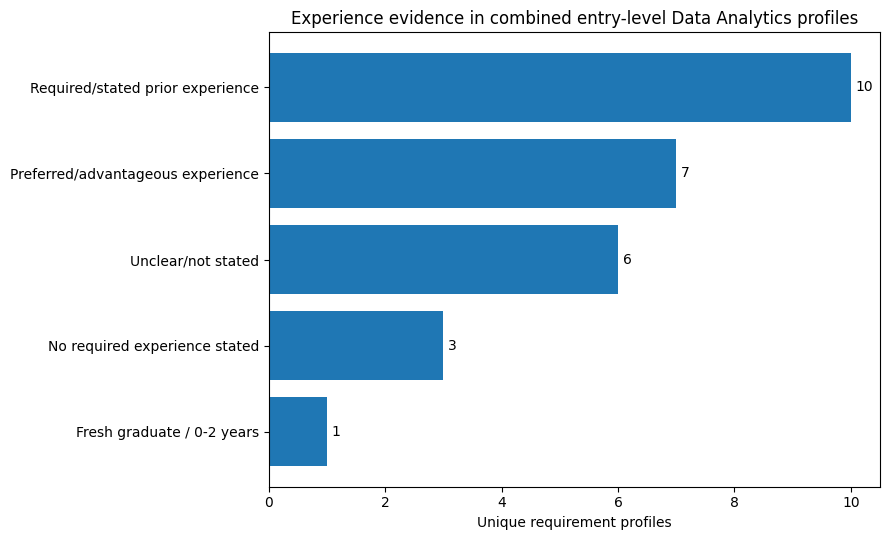

In [46]:
# @title
def classify_initial_experience(row):
    entry = str(row["Entry-Level Basis"]).lower()
    preferred = str(row["Preferred / Advantageous Skills"]).lower()
    combined = entry + " " + preferred

    explicit_required_phrases = [
        "at least 1 year of relevant professional experience",
        "also states 1-2 years",
        "also states 1–2 years",
        "1-4 years of experience is also listed",
        "1–4 years of experience is also listed",
        "but the posting also requires 1-2 years",
        "but the posting also requires 1–2 years",
    ]

    if any(p in entry for p in explicit_required_phrases):
        return "Required/stated prior experience"
    if "up to 2 years" in entry:
        return "Fresh graduate / 0-2 years"
    if any(p in combined for p in [
        "preferred", "advantageous", "an advantage", "only a plus", "is a plus"
    ]):
        return "Preferred/advantageous experience"
    if any(p in entry for p in [
        "fresh graduate", "fresh graduates", "entry-level",
        "early in their analytics career"
    ]):
        return "No required experience stated"
    return "Unclear/not stated"

def classify_simplify_experience(row):
    req = str(row.get("experience_required", "")).lower()
    pref = str(row.get("experience_preferred", "")).lower()
    band = str(row.get("experience_band_normalized", "")).lower()

    if "ideal but not essential" in req:
        return "Preferred/advantageous experience"

    if (
        re.search(r"\b(?:minimum|at least|required)\b.*?\b[12]\b\s*(?:years?|yrs?)", req)
        or re.search(r"\b[12]\+?\s*(?:years?|yrs?)", req)
    ):
        return "Required/stated prior experience"

    if "fresh graduates accepted" in band:
        return "No required experience stated"

    if "junior title; years not stated" in band:
        if (
            re.search(r"\b[123]\b\s*(?:years?|yrs?)", pref)
            or any(p in pref for p in ["plus", "preferred", "advantage"])
        ):
            return "Preferred/advantageous experience"
        return "Unclear/not stated"

    if "not clearly stated" in band:
        return "Unclear/not stated"

    if any(p in band for p in ["1+", "2+", "multiple experience statements"]):
        return "Required/stated prior experience"

    return "Unclear/not stated"

initial["experience_category"] = initial.apply(classify_initial_experience, axis=1)
simplify_unique["experience_category"] = simplify_unique.apply(classify_simplify_experience, axis=1)

experience_combined = pd.concat([
    simplify_unique[["company", "job_title", "experience_category"]]
        .rename(columns={"company":"Employer", "job_title":"Job title"})
        .assign(Source="SimplifyTrabaho"),
    initial[["Company", "Job Title", "experience_category", "Source"]]
        .rename(columns={"Company":"Employer", "Job Title":"Job title"})
], ignore_index=True)

experience_summary = (
    experience_combined["experience_category"]
    .value_counts()
    .rename_axis("Experience evidence")
    .reset_index(name="Profiles")
)

experience_summary["Percent"] = (
    experience_summary["Profiles"] / len(experience_combined) * 100
).round(1)

display(experience_summary)
experience_summary.to_csv(OUTPUT_DIR / "table_03_experience_evidence.csv", index=False)

plot_df = experience_summary.sort_values("Profiles")
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(plot_df["Experience evidence"], plot_df["Profiles"])
ax.set_title("Experience evidence in combined entry-level Data Analytics profiles")
ax.set_xlabel("Unique requirement profiles")
ax.set_ylabel("")
for i, v in enumerate(plot_df["Profiles"]):
    ax.text(v + 0.08, i, str(v), va="center")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "figure_01_experience_evidence.png", dpi=200, bbox_inches="tight")
plt.show()


In [47]:
# @title
required_exp = int(
    experience_summary.loc[
        experience_summary["Experience evidence"].eq("Required/stated prior experience"),
        "Profiles"
    ].sum()
)
preferred_exp = int(
    experience_summary.loc[
        experience_summary["Experience evidence"].eq("Preferred/advantageous experience"),
        "Profiles"
    ].sum()
)

display(Markdown(f'''
### Visual 1 analysis

Across **{len(experience_combined)} combined unique entry-level profiles**, **{required_exp}** contain required or clearly stated prior-experience evidence and **{preferred_exp}** treat experience as preferred or advantageous.

**Interpretation:** the evidence shows an entry-level-accessibility tension for part of the sample, but experience should be treated as a **job-readiness condition**, not automatically as a curriculum deficiency. A one- or two-year experience request can make entry more difficult for fresh graduates even where the required technical competencies are academically aligned.

**Limitation:** experience wording differs across postings and some records remain unclear. The chart describes the collected sample only.
'''))



### Visual 1 analysis

Across **27 combined unique entry-level profiles**, **10** contain required or clearly stated prior-experience evidence and **7** treat experience as preferred or advantageous.

**Interpretation:** the evidence shows an entry-level-accessibility tension for part of the sample, but experience should be treated as a **job-readiness condition**, not automatically as a curriculum deficiency. A one- or two-year experience request can make entry more difficult for fresh graduates even where the required technical competencies are academically aligned.

**Limitation:** experience wording differs across postings and some records remain unclear. The chart describes the collected sample only.


### Visual 2: Explicitly required vs preferred tools

**Analytical question:** Which concrete analytics tools are explicitly required, and which are merely preferred/advantageous?

**Correct unit:** unique profile-tool combination.

**Why this chart:** it directly prevents preferred technologies from being misrepresented as mandatory entry-level requirements.

For the automatically extracted SimplifyTrabaho records, only `Explicit required` and `Explicit preferred` evidence is used in this figure. Ambiguous mentions and role-responsibility references are not forced into either category.

**Decision:** **KEEP**.


requirement_type,tool,Preferred,Required,Total explicit
0,Excel,2,8,10
14,SQL,3,6,9
11,Python,5,2,7
10,Power BI,4,1,5
3,Google Sheets,0,4,4
17,Tableau,3,0,3
6,Looker Studio,2,0,2
7,MS Access,0,1,1
9,Power Automate,0,1,1
1,Figma,1,0,1


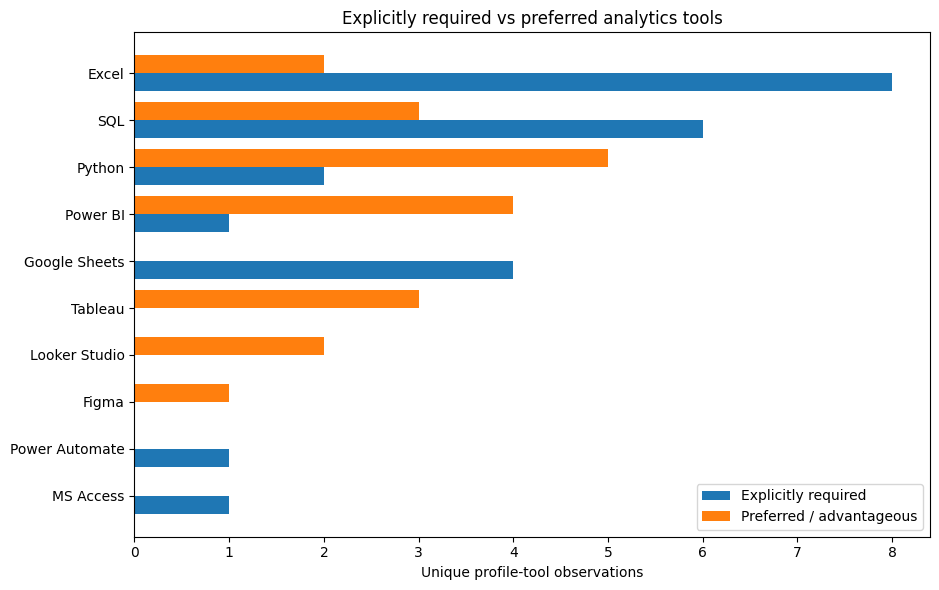

In [48]:
# @title
TOOL_PATTERNS = [
    ("Excel", r"\b(?:ms\s+)?excel\b"),
    ("Google Sheets", r"\bgoogle sheets\b|\bsheets\b"),
    ("SQL", r"\bsql\b"),
    ("Power BI", r"\bpower bi\b"),
    ("Tableau", r"\btableau\b"),
    ("Looker Studio", r"\blooker studio\b"),
    ("Python", r"\bpython\b"),
    ("R", r"(?<![A-Za-z])R(?![A-Za-z])"),
    ("Streamlit", r"\bstreamlit\b"),
    ("Google Analytics / GA4", r"\bga4\b|\bgoogle analytics\b"),
    ("HubSpot", r"\bhubspot\b"),
    ("Marketo", r"\bmarketo\b"),
    ("Salesforce", r"\bsalesforce\b"),
    ("Power Automate", r"\bpower automate\b"),
    ("MS Access", r"\baccess\b"),
    ("Figma", r"\bfigma\b"),
    ("C++", r"\bc\+\+\b"),
    ("Java", r"\bjava\b"),
]

manual_tool_rows = []
for _, row in initial.iterrows():
    for field, requirement_type in [
        ("Required Skills", "Required"),
        ("Preferred / Advantageous Skills", "Preferred")
    ]:
        text = str(row[field]) if pd.notna(row[field]) else ""
        for tool, pattern in TOOL_PATTERNS:
            if re.search(pattern, text, flags=re.I):
                manual_tool_rows.append({
                    "profile_key": "initial:" + row["dedup_key"],
                    "tool": tool,
                    "requirement_type": requirement_type
                })

manual_tools = pd.DataFrame(manual_tool_rows).drop_duplicates()

keep_profile_ids = set(simplify_unique["requirement_profile_id"])
simplify_skill_subset = skills_entry[
    skills_entry["requirement_profile_id"].isin(keep_profile_ids)
].copy()

simplify_tools = simplify_skill_subset[
    simplify_skill_subset["item_type"].eq("Tool")
].copy()

simplify_tools["requirement_type"] = simplify_tools[
    "requirement_evidence_normalized"
].map({
    "Explicit required": "Required",
    "Explicit preferred": "Preferred"
})

simplify_tools = simplify_tools[simplify_tools["requirement_type"].notna()].copy()
simplify_tools["profile_key"] = "simplify:" + simplify_tools["requirement_profile_id"].astype(str)

simplify_tools = simplify_tools[
    ["profile_key", "skill_normalized", "requirement_type"]
].rename(columns={"skill_normalized":"tool"})

combined_tools = pd.concat(
    [simplify_tools, manual_tools],
    ignore_index=True
).drop_duplicates()

tool_summary = (
    combined_tools
    .groupby(["tool", "requirement_type"])["profile_key"]
    .nunique()
    .unstack(fill_value=0)
    .reset_index()
)

for col in ["Required", "Preferred"]:
    if col not in tool_summary.columns:
        tool_summary[col] = 0

tool_summary["Total explicit"] = tool_summary["Required"] + tool_summary["Preferred"]
tool_summary = tool_summary.sort_values(
    ["Total explicit", "Required"], ascending=False
)

display(tool_summary)
tool_summary.to_csv(OUTPUT_DIR / "table_04_required_vs_preferred_tools.csv", index=False)

plot_df = tool_summary.head(10).sort_values("Total explicit")
y = np.arange(len(plot_df))
height = 0.38

fig, ax = plt.subplots(figsize=(9.5, 6))
ax.barh(y - height/2, plot_df["Required"], height, label="Explicitly required")
ax.barh(y + height/2, plot_df["Preferred"], height, label="Preferred / advantageous")
ax.set_yticks(y)
ax.set_yticklabels(plot_df["tool"])
ax.set_xlabel("Unique profile-tool observations")
ax.set_title("Explicitly required vs preferred analytics tools")
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "figure_02_required_vs_preferred_tools.png", dpi=200, bbox_inches="tight")
plt.show()


In [49]:
# @title
top_required = tool_summary.sort_values("Required", ascending=False).head(3)
top_preferred = tool_summary.sort_values("Preferred", ascending=False).head(3)

req_text = "\n".join(
    f"- **{r['tool']}**: explicitly required in {int(r['Required'])} unique profile(s)."
    for _, r in top_required.iterrows()
)
pref_text = "\n".join(
    f"- **{r['tool']}**: preferred/advantageous in {int(r['Preferred'])} unique profile(s)."
    for _, r in top_preferred.iterrows()
)

display(Markdown(f'''
### Visual 2 analysis

**Most frequent explicit requirements**
{req_text}

**Most frequent preferred/advantageous tools**
{pref_text}

**Interpretation:** employer postings distinguish foundational requirements from additional specialization. A tool appearing frequently in the preferred category should not be treated as evidence that all fresh graduates are required to possess it.

**Limitation:** automatically extracted postings contain many ambiguous tool mentions. This figure intentionally excludes those ambiguous cases rather than guessing whether they are required or preferred.
'''))



### Visual 2 analysis

**Most frequent explicit requirements**
- **Excel**: explicitly required in 8 unique profile(s).
- **SQL**: explicitly required in 6 unique profile(s).
- **Google Sheets**: explicitly required in 4 unique profile(s).

**Most frequent preferred/advantageous tools**
- **Python**: preferred/advantageous in 5 unique profile(s).
- **Power BI**: preferred/advantageous in 4 unique profile(s).
- **Tableau**: preferred/advantageous in 3 unique profile(s).

**Interpretation:** employer postings distinguish foundational requirements from additional specialization. A tool appearing frequently in the preferred category should not be treated as evidence that all fresh graduates are required to possess it.

**Limitation:** automatically extracted postings contain many ambiguous tool mentions. This figure intentionally excludes those ambiguous cases rather than guessing whether they are required or preferred.


## 5. Requirement 3: Compare employer evidence with the HEI curriculum baseline

### Visual 3: Employer competency evidence vs documented HEI coverage

**Analytical question:** Do the broad competencies observed in entry-level employer profiles also appear in the selected HEI curriculum/graduate-competency sources?

**Correct units:**
- Employer side: combined unique entry-level requirement profile
- HEI side: institution with sufficient public curriculum/competency evidence

**Why this chart:** broad competency categories are more comparable across employers and curricula than specific software tools.

**Decision:** **KEEP**. This is the principal synthesis visual for mentor feedback #3.


,Competency,Employer profiles,Employer denominator,Employer percent,HEIs documenting competency,HEI denominator,HEI percent
0,Data preparation,16,27,59.3,3,8,37.5
1,Data analysis / EDA,16,27,59.3,8,8,100.0
2,Statistics / quantitative,8,27,29.6,6,8,75.0
3,Database / data management,19,27,70.4,7,8,87.5
4,Visualization / dashboards,15,27,55.6,4,8,50.0
5,Reporting / communication,21,27,77.8,6,8,75.0
6,Programming for analytics,11,27,40.7,7,8,87.5
7,Data mining / ML / predictive,2,27,7.4,5,8,62.5
8,BI / decision support,9,27,33.3,6,8,75.0


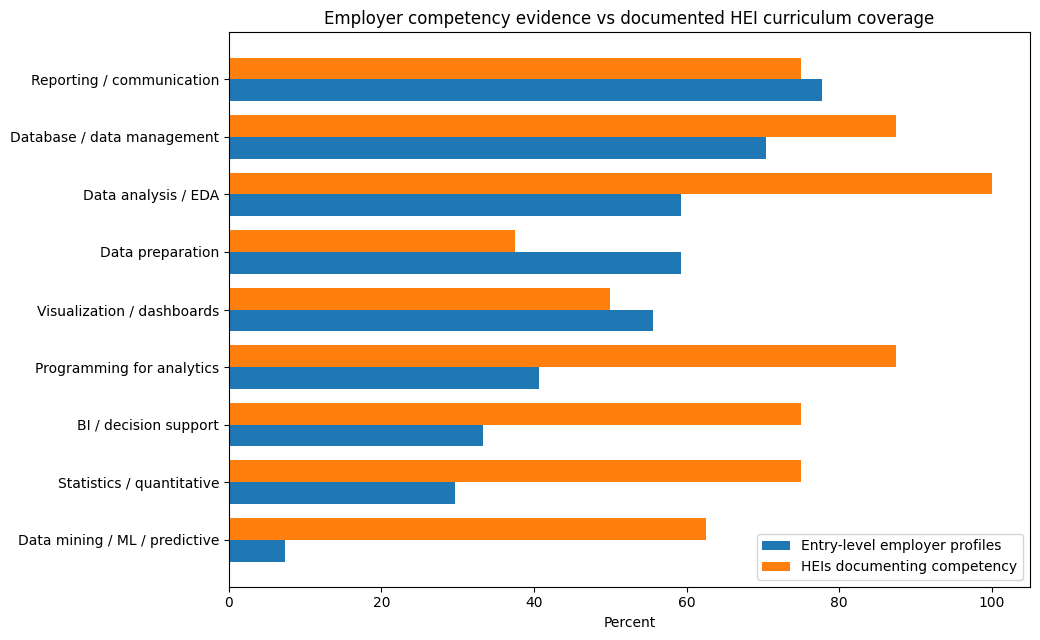

In [50]:
# @title
COMPETENCY_PATTERNS = [
    ("Data preparation & quality", r"data cleaning|data cleansing|data validation|\bqa\b|data quality|data gathering|data collection|data transformation|data processing|data matching"),
    ("Data analysis", r"data analysis|business data analysis|\beda\b|analytical"),
    ("Reporting & communication", r"report|reporting|presentation|communication|documentation|insights|recommendations"),
    ("Visualization & dashboards", r"visualization|dashboard"),
    ("Database & querying", r"database|\bsql\b|query|relational database"),
    ("Statistics & quantitative analysis", r"statistic|statistical|segmentation|trend|pattern"),
    ("Programming for analytics", r"python|scripting|\br\b|c\+\+|java"),
    ("Machine learning & predictive analytics", r"machine learning|predictive analytics|data mining"),
    ("Business intelligence & decision support", r"\bbi\b|business intelligence"),
]

manual_comp_rows = []
for _, row in initial.iterrows():
    for field in ["Required Skills", "Preferred / Advantageous Skills"]:
        text = str(row[field]) if pd.notna(row[field]) else ""
        for competency, pattern in COMPETENCY_PATTERNS:
            if re.search(pattern, text, flags=re.I):
                manual_comp_rows.append({
                    "profile_key": "initial:" + row["dedup_key"],
                    "competency_group": competency
                })

manual_comp = pd.DataFrame(manual_comp_rows).drop_duplicates()

simplify_comp = simplify_skill_subset[
    ["requirement_profile_id", "competency_group"]
].drop_duplicates().copy()
simplify_comp["profile_key"] = (
    "simplify:" + simplify_comp["requirement_profile_id"].astype(str)
)
simplify_comp = simplify_comp[["profile_key", "competency_group"]]

combined_comp = pd.concat(
    [simplify_comp, manual_comp],
    ignore_index=True
).drop_duplicates()

COMPETENCY_LABELS = {
    "data_collection_preparation": "Data preparation",
    "data_analysis_eda": "Data analysis / EDA",
    "statistics_quantitative": "Statistics / quantitative",
    "database_data_management": "Database / data management",
    "visualization_dashboards": "Visualization / dashboards",
    "reporting_communication": "Reporting / communication",
    "programming_for_analytics": "Programming for analytics",
    "data_mining_ml_predictive": "Data mining / ML / predictive",
    "business_intelligence_decision_support": "BI / decision support",
}

JOB_TO_CURRICULUM = {
    "Data preparation & quality": "data_collection_preparation",
    "Data analysis": "data_analysis_eda",
    "Statistics & quantitative analysis": "statistics_quantitative",
    "Database & querying": "database_data_management",
    "Data management & modeling": "database_data_management",
    "Visualization & dashboards": "visualization_dashboards",
    "Reporting & communication": "reporting_communication",
    "Programming for analytics": "programming_for_analytics",
    "Machine learning & predictive analytics": "data_mining_ml_predictive",
    "Business intelligence & decision support": "business_intelligence_decision_support",
}

mapped = combined_comp[
    combined_comp["competency_group"].isin(JOB_TO_CURRICULUM)
].copy()
mapped["curriculum_competency"] = mapped["competency_group"].map(JOB_TO_CURRICULUM)
mapped = mapped.drop_duplicates(["profile_key", "curriculum_competency"])

employer_counts = (
    mapped.groupby("curriculum_competency")["profile_key"]
    .nunique()
)

included_institutions = set(
    hei_inventory.loc[
        hei_inventory["include_in_competency_counts"].str.lower().eq("yes"),
        "institution"
    ]
)
hei_included = hei_matrix[
    hei_matrix["institution"].isin(included_institutions)
].copy()

comparison_rows = []
for code, label in COMPETENCY_LABELS.items():
    employer_n = int(employer_counts.get(code, 0))
    hei_n = int(hei_included[code].eq("D").sum())

    comparison_rows.append({
        "Competency": label,
        "Employer profiles": employer_n,
        "Employer denominator": combined_profile_count,
        "Employer percent": round(employer_n / combined_profile_count * 100, 1),
        "HEIs documenting competency": hei_n,
        "HEI denominator": len(hei_included),
        "HEI percent": round(hei_n / len(hei_included) * 100, 1),
    })

comparison = pd.DataFrame(comparison_rows)
display(comparison)
comparison.to_csv(OUTPUT_DIR / "table_05_employer_vs_hei_competencies.csv", index=False)

plot_df = comparison.sort_values("Employer percent")
y = np.arange(len(plot_df))
height = 0.38

fig, ax = plt.subplots(figsize=(10.5, 6.5))
ax.barh(
    y - height/2,
    plot_df["Employer percent"],
    height,
    label="Entry-level employer profiles"
)
ax.barh(
    y + height/2,
    plot_df["HEI percent"],
    height,
    label="HEIs documenting competency"
)

ax.set_yticks(y)
ax.set_yticklabels(plot_df["Competency"])
ax.set_xlabel("Percent")
ax.set_title("Employer competency evidence vs documented HEI curriculum coverage")
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "figure_03_employer_vs_hei.png", dpi=200, bbox_inches="tight")
plt.show()


In [51]:
# @title
top_employer = comparison.sort_values("Employer percent", ascending=False).head(4)
top_hei = comparison.sort_values("HEI percent", ascending=False).head(4)

employer_text = "\n".join(
    f"- **{r['Competency']}**: {int(r['Employer profiles'])}/{int(r['Employer denominator'])} profiles ({r['Employer percent']:.1f}%)."
    for _, r in top_employer.iterrows()
)

hei_text = "\n".join(
    f"- **{r['Competency']}**: {int(r['HEIs documenting competency'])}/{int(r['HEI denominator'])} HEIs ({r['HEI percent']:.1f}%)."
    for _, r in top_hei.iterrows()
)

display(Markdown(f'''
### Visual 3 analysis

**Most frequently observed employer-side competencies**
{employer_text}

**Most widely documented HEI competencies**
{hei_text}

**Interpretation:** the evidence shows meaningful overlap between employer expectations and the documented academic baseline in several foundational areas. The employer side is often more specific about implementation context and tools, while the HEI side more often documents broader competencies.

**Limitation:** the percentages are not directly equivalent measurements. Employer percentages represent requirement profiles; HEI percentages represent documented curriculum coverage. This figure is a descriptive comparison, not an alignment score.
'''))



### Visual 3 analysis

**Most frequently observed employer-side competencies**
- **Reporting / communication**: 21/27 profiles (77.8%).
- **Database / data management**: 19/27 profiles (70.4%).
- **Data preparation**: 16/27 profiles (59.3%).
- **Data analysis / EDA**: 16/27 profiles (59.3%).

**Most widely documented HEI competencies**
- **Data analysis / EDA**: 8/8 HEIs (100.0%).
- **Programming for analytics**: 7/8 HEIs (87.5%).
- **Database / data management**: 7/8 HEIs (87.5%).
- **BI / decision support**: 6/8 HEIs (75.0%).

**Interpretation:** the evidence shows meaningful overlap between employer expectations and the documented academic baseline in several foundational areas. The employer side is often more specific about implementation context and tools, while the HEI side more often documents broader competencies.

**Limitation:** the percentages are not directly equivalent measurements. Employer percentages represent requirement profiles; HEI percentages represent documented curriculum coverage. This figure is a descriptive comparison, not an alignment score.


## 6. Supporting qualitative check: the original 11 manual postings

The earlier evidence table already classified each manually gathered posting as against, mixed, or supporting the proposed mismatch. These labels are summarized here only as a **qualitative cross-check**, not as an independent statistical test.


In [52]:
# @title
initial_assessment_summary = (
    initial["prior_assessment_normalized"]
    .value_counts()
    .rename_axis("Prior qualitative assessment")
    .reset_index(name="Postings")
)

initial_assessment_summary["Percent"] = (
    initial_assessment_summary["Postings"] / len(initial) * 100
).round(1)

display(initial_assessment_summary)
initial_assessment_summary.to_csv(
    OUTPUT_DIR / "table_06_initial_qualitative_assessment.csv", index=False
)


,Prior qualitative assessment,Postings,Percent
0,Mixed / conditional evidence,6,54.5
1,Does not support broad mismatch,4,36.4
2,Supports potential mismatch,1,9.1


## 7. Final synthesis: Does the current evidence affirm a mismatch?

The conclusion below deliberately distinguishes a **broad mismatch claim** from **partial or conditional alignment tensions**.


In [53]:
# @title
assessment_counts = initial["prior_assessment_normalized"].value_counts()
against_n = int(assessment_counts.get("Does not support broad mismatch", 0))
mixed_n = int(assessment_counts.get("Mixed / conditional evidence", 0))
support_n = int(assessment_counts.get("Supports potential mismatch", 0))

required_exp_n = int(
    experience_summary.loc[
        experience_summary["Experience evidence"].eq("Required/stated prior experience"),
        "Profiles"
    ].sum()
)

top_emp = comparison.sort_values("Employer percent", ascending=False).iloc[0]
top_hei_row = comparison.sort_values("HEI percent", ascending=False).iloc[0]

display(Markdown(f'''
# Summary of analysis

## Overall finding

### **Broad graduate-employer mismatch: NOT AFFIRMED by the current evidence.**

The collected evidence does **not** support a defensible conclusion that fresh graduates from Philippine computing and analytics-oriented programs are broadly unprepared for entry-level Data Analytics work.

Instead, the evidence supports a more limited conclusion:

### **Partial or conditional alignment tensions are present.**

These tensions appear mainly in two areas:

1. **Prior-experience expectations.**
   **{required_exp_n} of {combined_profile_count}** combined unique entry-level profiles contain required or clearly stated prior-experience evidence. This can create a job-readiness barrier for fresh graduates even when their academic competencies are relevant.

2. **Tool-specific or specialized employer expectations.**
   Employers sometimes name specific software, languages, platforms, or domain tools. The required-versus-preferred analysis shows that many of these technologies are advantageous rather than universally mandatory.

## Curriculum comparison

The curriculum comparison shows substantial documented coverage of foundational competencies across the selected HEIs. For example, the employer-side competency most frequently observed is **{top_emp["Competency"]}**, while the most widely documented HEI competency is **{top_hei_row["Competency"]}**.

This pattern is more consistent with **partial alignment plus job-readiness friction** than with a simple claim that academic preparation is broadly mismatched with employer demand.

## Initial-evidence cross-check

Among the **{len(initial)} manually reviewed JobStreet, LinkedIn, and Indeed postings**:

- **{against_n}** did not support a broad mismatch claim,
- **{mixed_n}** provided mixed or conditional evidence,
- **{support_n}** provided stronger evidence of a potential mismatch.

The original evidence therefore also points toward a conditional rather than universal mismatch.

## Required disclaimer

**This conclusion is limited to the job postings, curriculum documents, and competency evidence gathered for this study. It should not be generalized to all Philippine employers, all higher-education institutions, or all fresh graduates. The observed pattern may change if a larger, more geographically diverse, or more recent set of job postings and curriculum sources is collected and analyzed.**

The curriculum baseline is also limited to competencies explicitly documented in publicly accessible official materials. Missing public documentation does not establish that a competency is absent from the actual curriculum, and documented curriculum coverage does not prove graduate mastery.
'''))



# Summary of analysis

## Overall finding

### **Broad graduate-employer mismatch: NOT AFFIRMED by the current evidence.**

The collected evidence does **not** support a defensible conclusion that fresh graduates from Philippine computing and analytics-oriented programs are broadly unprepared for entry-level Data Analytics work.

Instead, the evidence supports a more limited conclusion:

### **Partial or conditional alignment tensions are present.**

These tensions appear mainly in two areas:

1. **Prior-experience expectations.**  
   **10 of 27** combined unique entry-level profiles contain required or clearly stated prior-experience evidence. This can create a job-readiness barrier for fresh graduates even when their academic competencies are relevant.

2. **Tool-specific or specialized employer expectations.**  
   Employers sometimes name specific software, languages, platforms, or domain tools. The required-versus-preferred analysis shows that many of these technologies are advantageous rather than universally mandatory.

## Curriculum comparison

The curriculum comparison shows substantial documented coverage of foundational competencies across the selected HEIs. For example, the employer-side competency most frequently observed is **Reporting / communication**, while the most widely documented HEI competency is **Data analysis / EDA**.

This pattern is more consistent with **partial alignment plus job-readiness friction** than with a simple claim that academic preparation is broadly mismatched with employer demand.

## Initial-evidence cross-check

Among the **11 manually reviewed JobStreet, LinkedIn, and Indeed postings**:

- **4** did not support a broad mismatch claim,
- **6** provided mixed or conditional evidence,
- **1** provided stronger evidence of a potential mismatch.

The original evidence therefore also points toward a conditional rather than universal mismatch.

## Required disclaimer

**This conclusion is limited to the job postings, curriculum documents, and competency evidence gathered for this study. It should not be generalized to all Philippine employers, all higher-education institutions, or all fresh graduates. The observed pattern may change if a larger, more geographically diverse, or more recent set of job postings and curriculum sources is collected and analyzed.**

The curriculum baseline is also limited to competencies explicitly documented in publicly accessible official materials. Missing public documentation does not establish that a competency is absent from the actual curriculum, and documented curriculum coverage does not prove graduate mastery.


## 8. Appendix-ready tables

The following outputs preserve evidence traceability without adding more figures to Chapter II.


In [54]:
# @title
# Appendix table: manually gathered evidence
appendix_initial = initial[[
    "Source", "Link", "Job Title", "Company", "Entry-Level Basis",
    "Education", "Required Skills", "Preferred / Advantageous Skills",
    "prior_assessment_normalized"
]].copy()

display(appendix_initial)
appendix_initial.to_csv(
    OUTPUT_DIR / "appendix_initial_job_postings.csv", index=False
)

# Appendix table: HEI source inventory
appendix_hei = hei_inventory[[
    "institution", "program", "region", "evidence_level",
    "include_in_competency_counts", "evidence_summary", "source_url"
]].copy()

display(appendix_hei)
appendix_hei.to_csv(
    OUTPUT_DIR / "appendix_hei_source_inventory.csv", index=False
)


,Source,Link,Job Title,Company,Entry-Level Basis,Education,Required Skills,Preferred / Advantageous Skills,prior_assessment_normalized
0,JobStreet,https://ph.jobstreet.com/job/94991156?ref=search-standalone&type=standard&origin=showNewTab#sol=3d99c6acd1dfc76e96dddedc35ea5ab047223018,Junior Data Analyst,"CNT Promo & Ads Specialist, Inc.",Fresh graduates are welcome to apply; 1-3 years of relevant experience is an advantage,"BS Information Technology, Computer Science, Information Systems, or another computer/data-related course","Excel functions (XLOOKUP/VLOOKUP, INDEX-MATCH, IF, SUMIFS), Pivot Tables, data cleaning, data validation, data analysis, reporting, anal...","1-3 years of experience; Power BI, SQL, Google Looker Studio, HRIS, payroll/timekeeping systems, data visualization, AI tools and automa...",Mixed / conditional evidence
1,JobStreet,https://ph.jobstreet.com/job/94905913?ref=search-standalone&type=standard&origin=showNewTab#sol=e175420a5b526590cd753b8b7582791599bf9da7,CRM Junior Data Analyst,RUSTAN COMMERCIAL CORPORATION,Open to fresh graduates or applicants with at least 1 year of experience as a Data Analyst,"Bachelor's degree in Business Administration/Management, Marketing Management, or related courses; BS Computer Science, BS Information T...","Data gathering, data analysis, report creation, research, insights and recommendations, MS Excel, MS PowerPoint, Google Sheets, Google S...","1 year of experience in data gathering, cleansing, and reporting; SQL knowledge is preferred",Does not support broad mismatch
2,JobStreet,https://ph.jobstreet.com/job/95001315?ref=search-standalone&type=standard&origin=showNewTab#sol=ced7b7994963e2c2d864b72a087b7be173f32d5e,Junior Data Analyst,DOCQUITY PHILIPPINES CORPORATION,Fresh graduates with strong analytics projects can be considered; 1-2+ years of data analysis experience is preferred,"Bachelor's degree in Data Science, Statistics, Physics, Mathematics, Computer Science, or related fields","Data analysis, SQL, data visualization, data validation and QA, attention to detail, data accuracy, communication, problem-solving, abil...","1-2+ years of data analysis experience, Tableau, Power BI, Streamlit, and Python",Mixed / conditional evidence
3,JobStreet,https://ph.jobstreet.com/job/95039137?ref=search-standalone&type=standard&origin=showNewTab#sol=bc84a49a9c316f612ebcd1ce35ee70aa28df145e,Entry Level Data Analyst,Private Advertiser,Explicitly states that fresh graduates are welcome to apply,"Graduate of any relevant course; IT, Computer Science, Statistics, Mathematics, or related fields are advantageous","Microsoft Excel, MS Office, data collection, data encoding/consolidation, data validation, data analysis, reporting, database/spreadshee...",Not Specified,Does not support broad mismatch
4,LinkedIn,https://www.linkedin.com/jobs/view/4452727120/,Junior Data Analyst,Electronic Transfer and Advance Processing Inc. (eTap Inc.),"Fresh graduates with relevant internships, academic projects, or technical training are encouraged to apply","Bachelor's degree in Data Science, Statistics, Mathematics, Computer Science, Information Technology, Business Analytics, Economics, or ...","Data collection, cleaning, transformation, organization, SQL, Excel/Google Sheets, data validation, QA, anomaly identification, basic ED...","ETL/data pipelines, Power BI/Tableau/Looker Studio, Python/R, automation, data pipeline development",Does not support broad mismatch
5,LinkedIn,https://www.linkedin.com/jobs/view/4465059170/,Junior Analytics Specialist,Spiralyze,Early in their analytics career; around 1 year of analytics experience is only a plus; entry-level roles are explicitly referenced,Not Specified,"Google Sheets, English communication, data literacy, attention to detail, data analysis, identifying data anomalies/root causes, require...","GA4, HubSpot, Marketo, Salesforce, and around 1 year of analytics experience",Does not support broad mismatch
6,LinkedIn,https://www.linkedin.com/jobs/view/447

,institution,program,region,evidence_level,include_in_competency_counts,evidence_summary,source_url
0,Mapúa Malayan Digital College,"BS Information Technology, Data Analytics",National / Online,Strong course and competency evidence,Yes,"Program page identifies data cleaning, transformation, analysis and dashboards; course list includes Information Management, Database Pr...",https://www.mmdc.mcl.edu.ph/college-programs/data-analytics/
1,University of Santo Tomas,BS Data Science and Analytics,NCR,Full curriculum,Yes,"Official curriculum lists programming for data science, exploratory data analysis, visualization, statistical inference, data management...",https://www.ust.edu.ph/academics/programs/bachelor-of-science-in-data-science-and-analytics/
2,De La Salle University,BS Data Science,NCR,Strong competency evidence,Yes,"Official program outcomes identify data collection, organization and analysis; ethical use of data; Python, R and Tableau; and communica...",https://old.dlsu.edu.ph/colleges/ccs/undergraduate-degree-programs/bsds/
3,Mapúa University,BS Data Science,NCR,Strong competency evidence,Yes,"Official program page explicitly identifies Data Analysis, Python and R, Machine Learning Techniques and Statistical Modeling. A full se...",https://www.mapua.edu.ph/pages/academics/undergraduate/makati-campus/school-of-information-technology/bachelor-of-science-in-data-science
4,FEU Institute of Technology,"BS Information Technology, Business Analytics",NCR,Strong competency evidence,Yes,"Official specialization page explicitly identifies data gathering, data storing, data analysis and interpretation, data application, sta...",https://feutech.edu.ph/academics/bsitba
5,Nueva Vizcaya State University,"BS Information Systems, Business Analytics",Region II,Program and competency evidence,Yes,"Official BSIS page identifies database management, business analytics, data management and analytical skills for decision support, and a...",https://cite.nvsu.edu.ph/academics/degree-programs/bsis
6,University of Science and Technology of Southern Philippines,BS Data Science,Northern Mindanao,Full curriculum,Yes,"Official curriculum includes programming, statistics, visualization and storytelling, databases, exploratory data analysis, data mining,...",https://www.ustp.edu.ph/cdeo/citc/bsds/
7,University of the Immaculate Conception,"BS Information Technology, Analytics and Machine Intelligence concentration",Davao / Mindanao,Full BSIT prospectus with analytics concentration,Yes,"2023 BSIT prospectus lists Quantitative Methods, Mathematics for Machine Learning, Information Management, Advanced Database Systems, Ma...",https://ccs.uic.edu.ph/academics/program-specifications/bsit-program-specifications
8,University of the Cordilleras,BS Data Analytics,CAR,Program offering only,No,"Official program page confirms a BS Data Analytics offering, but the collected public material does not provide enough course-level or c...",https://citcs.uc-bcf.edu.ph/programs/
9,University of San Carlos,BS Data Science,Cebu / Visayas,Program offering only,No,Official undergraduate listing confirms a BS Data Science program under the Department of Computer and Information Sciences and Mathemat...,https://usc.edu.ph/catholic-educational-institution-academics/undergraduate-programs


## 9. Export manifest

In [55]:
# @title
manifest = pd.DataFrame({
    "Output file": sorted(p.name for p in OUTPUT_DIR.iterdir())
})
display(manifest)


,Output file
0,appendix_employer_identity_table.csv
1,appendix_entry_level_job_profiles.csv
2,appendix_hei_source_inventory.csv
3,appendix_hei_source_table.csv
4,appendix_initial_job_postings.csv
5,figure_01_experience_evidence.png
6,figure_01_role_families.png
7,figure_02_experience.png
8,figure_02_required_vs_preferred_tools.png
9,figure_03_education.png
